# Diabetes Risk Screening with Logistic Regression

*Notebook 1 of 3 · Healthcare analytics*

A screening programme can't run a confirmatory blood test on everyone. This notebook asks whether a handful of routine clinical measurements can tell us who to test first, and how much of the model's output we can actually trust.

**Data:** Pima Indians Diabetes dataset, 768 patients, 8 clinical predictors, binary outcome (`../data/diabetes.csv`).
**Method:** binary logistic regression (scikit-learn for prediction, statsmodels for p-values), following an 8-step workflow: objective, data understanding, cleaning, variable roles, modelling, visuals, business interpretation, conclusion.

---

## Quick primer: logistic regression

Logistic regression predicts the **probability** that an observation belongs to a class. It maps any real number into (0, 1) with the sigmoid function:

> **σ(z) = 1 / (1 + e⁻ᶻ)**  where  **z = b₀ + b₁x₁ + … + bₙxₙ**

If σ(z) ≥ 0.5 we predict class 1, otherwise class 0. That 0.5 cut-off is a default, not a law, and Problem 1 shows why it matters.

| Type | Target categories | Example |
|---|---|---|
| Binomial | 2 | Yes/No, Fraud/Not-fraud |
| Multinomial | 3+, unordered | cat / dog / sheep |
| Ordinal | 3+, ordered | low / medium / high |

**Five assumptions**
1. Independent observations
2. Binary dependent variable (otherwise use softmax)
3. Linearity in the log-odds, i.e. predictors are linear in log(p/(1-p)), not in p
4. No extreme outliers
5. Enough data: a common rule of thumb is at least 10 events per predictor (EPV)

| Metric | Meaning |
|---|---|
| Coefficient (β) | change in **log-odds** per 1-unit rise in X |
| Odds ratio = e^β | multiplicative change in **odds** per 1-unit rise in X |
| OR = 1 / > 1 / < 1 | no association / raises odds / lowers odds |


In [1]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score, precision_recall_curve)

## Step 1 — Industry Objective

**Industry Context:**Healthcare / Preventive Screening

**Objective:**Help a diabetes screening programme identify high-risk patients from routine
clinical measurements, so limited diagnostic resources are directed at those most likely to
test positive.

**Research Questions:**
- **RQ1:**Which clinical measurements (glucose, BMI, family history, age) significantly
  predict whether a patient tests positive for diabetes?
- **RQ2:**How accurately can a logistic regression model classify patients as diabetic
  or non-diabetic?
- **RQ3:**Which risk factors should a screening programme prioritise to maximise
  early detection at the lowest cost?

## Step 2 — Understand the Data (Descriptive Analytics)



In [2]:
data = pd.read_csv('../data/diabetes.csv')

In [3]:
data.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Summary statistics
data.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [5]:
# Structure and class balance
data.info()
print("Target distribution (Outcome):")
print(data['Outcome'].value_counts())
print(f"Positive (diabetic) rate: {data['Outcome'].mean()*100:.1f}%")

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB
Target distribution (Outcome):
Outcome
0    500
1    268
Name: count, dtype: int64
Positive (diabetic) rate: 34.9%


**What the summary statistics say**

| Variable | Mean | SD | Note |
|----------|------|----|------|
| Pregnancies | 3.85 | 3.37 | Count variable |
| Glucose | 120.9 | 32.0 | Plasma glucose (mg/dL). Normal < 100, pre-diabetes 100–125, diabetes ≥ 126 |
| BloodPressure | 69.1 | 19.4 | Diastolic (mm Hg) |
| SkinThickness | 20.5 | 16.0 | Triceps skinfold (mm), a body-fat proxy. About 30% of values are zero |
| Insulin | 79.8 | 115.2 | 2-hour serum insulin. About 49% of values are zero |
| BMI | 32.0 | 7.9 | Mean is already in the obese range (≥ 30) |
| DiabetesPedigreeFunction | 0.47 | 0.33 | Family-history score |
| Age | 33.2 | 11.8 | Years, skewed toward younger patients |
| Outcome | 0.35 | n/a | 34.9% test positive (268 of 768) |

Three things stand out:

- **The zeros are not real.** Nobody has a glucose reading of 0 or a BMI of 0. These are missing values recorded as zero, and the means above are dragged down by them. Step 3 deals with this.
- **The classes are moderately imbalanced.** A model that said "no diabetes" for everyone would be right 65% of the time, so accuracy has to be judged against that 65% floor, not against 50%.
- **This is a high-baseline-risk group.** The average BMI sits in the obese range.

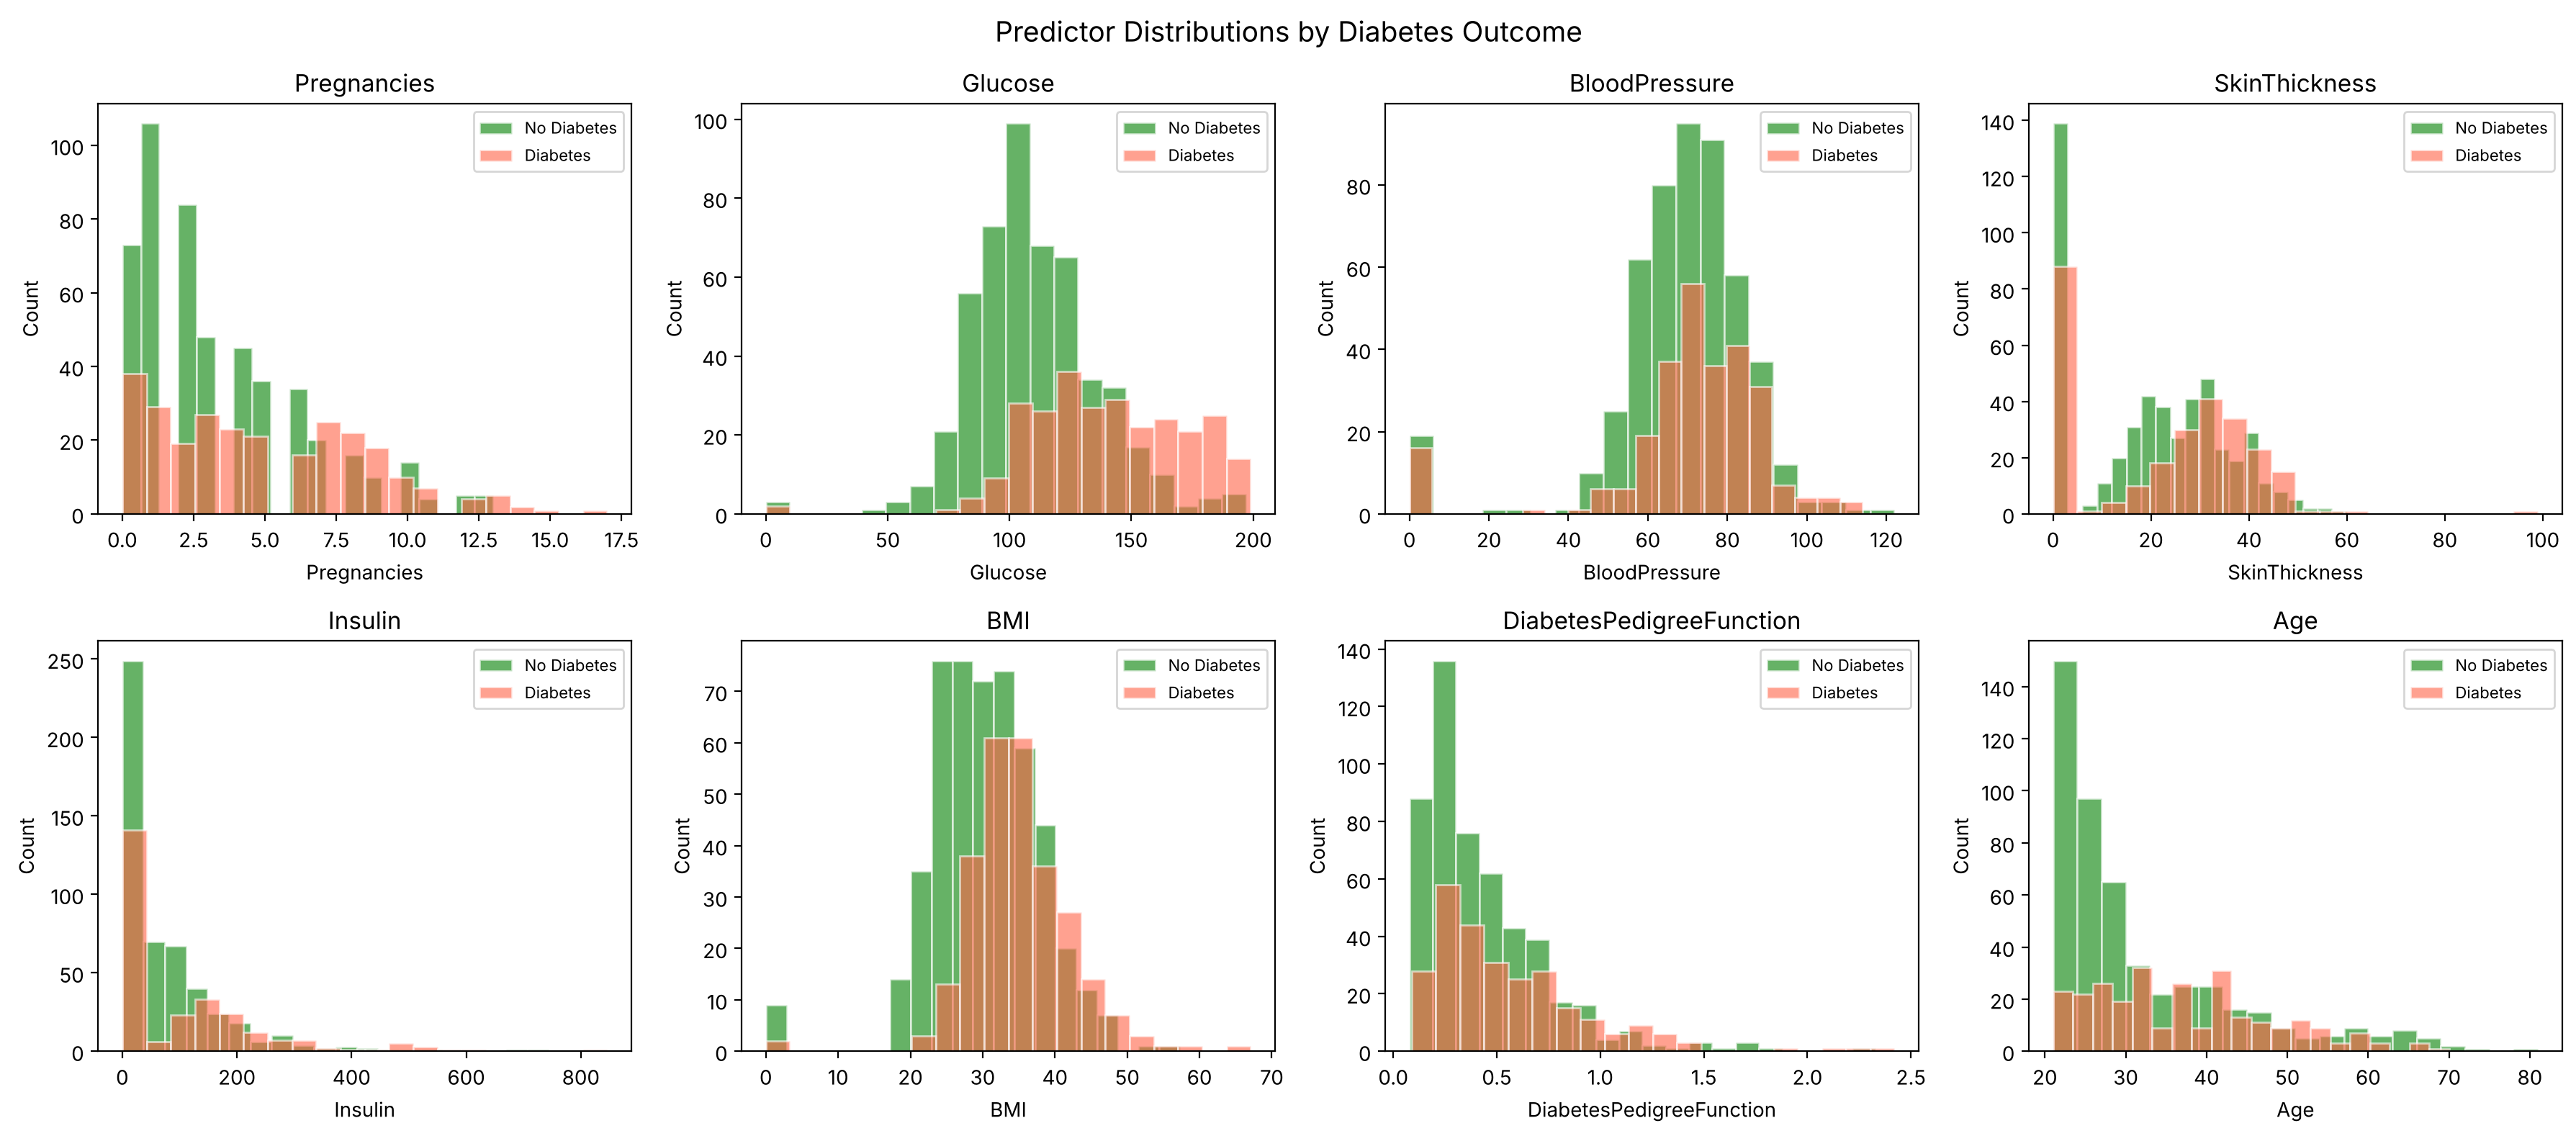

In [6]:
# Distribution of each predictor by Outcome
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, data.columns[:-1]):
    for outcome, colour, lbl in [(0,'green','No Diabetes'), (1,'tomato','Diabetes')]:
        ax.hist(data.loc[data.Outcome==outcome, col], bins=20, alpha=0.6,
                color=colour, label=lbl, edgecolor='white')
    ax.set(title=col, xlabel=col, ylabel='Count')
    ax.legend(fontsize=8)
plt.suptitle('Predictor Distributions by Diabetes Outcome', fontsize=14)
plt.tight_layout(); plt.show()

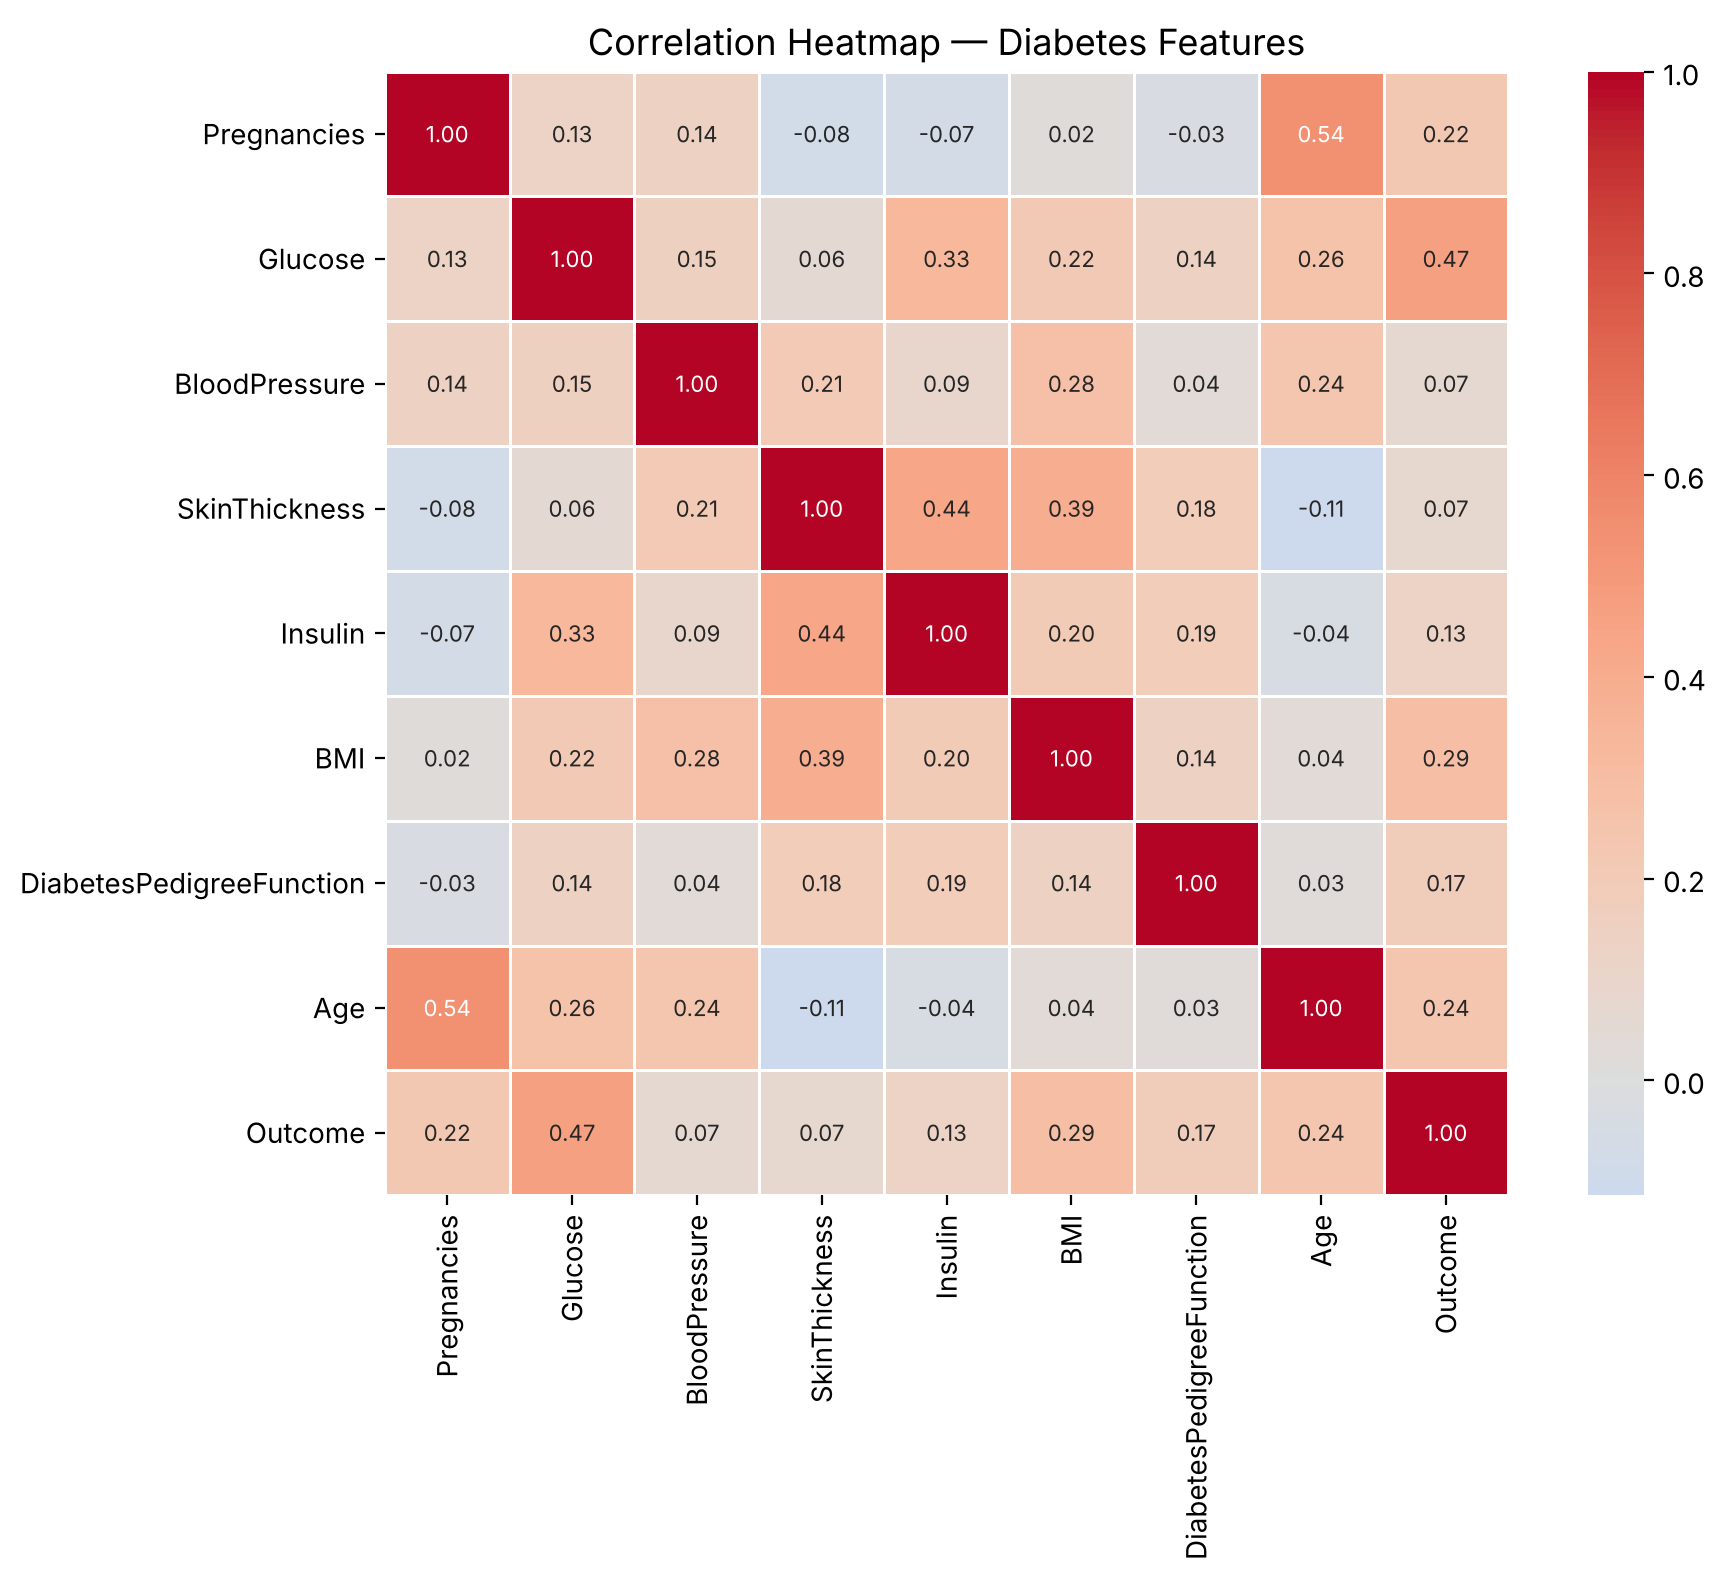

In [7]:
corr = data.corr(numeric_only=True)
plt.figure(figsize=(10,8))
sns.heatmap(
  corr,
  annot=True,
  fmt='.2f',
  cmap='coolwarm',
  center=0,
  square=True,
  linewidths=0.5,
  annot_kws={'size':8})
plt.title('Correlation Heatmap — Diabetes Features', fontsize=13)
plt.tight_layout(); plt.show()

**Graph Interpretation — Distributions by Outcome:**
- **Glucose**shows the clearest separation — the diabetic (red) distribution is visibly
  shifted right. This is the strongest visual discriminator and confirms its clinical role.
- **BMI**also separates, with diabetics concentrated at higher values.
- **Insulin and SkinThickness**show a large spike at **zero**in *both* classes — the
  missing-data artefact, not a real signal.
- **BloodPressure**shows heavily overlapping distributions, previewing its weak
  (and negative) coefficient in the model.

**Reading the correlation heatmap**

- Glucose has the strongest correlation with the outcome (0.47), followed by BMI (0.29), Age (0.24) and Pregnancies (0.22). That matches clinical expectations.
- The strongest correlation between two predictors is Pregnancies and Age (0.54), which is unsurprising. Insulin and Glucose are also related (0.33).
- No pair of predictors goes above |r| = 0.55, so multicollinearity is not a serious concern and nothing needs to be dropped on that basis.
- BloodPressure is almost uncorrelated with the outcome (0.065), an early sign that it will contribute little.

In [8]:
# Which features move with the outcome?
print("Correlation with Outcome (sorted):")
print(data.corr()['Outcome'].drop('Outcome').sort_values(ascending=False).round(3))

Correlation with Outcome (sorted):
Glucose                     0.467
BMI                         0.293
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
Insulin                     0.131
SkinThickness               0.075
BloodPressure               0.065
Name: Outcome, dtype: float64


## Step 3 — Data Cleaning

In [9]:
# 3a. Formal missing-value check
print("Explicit NaN values:")
print(data.isnull().sum())
print(f"Duplicate rows: {data.duplicated().sum()}")

Explicit NaN values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Duplicate rows: 0


In [10]:
# 3b. THE REAL ISSUE — zeros that are biologically impossible
zero_cols = ['Glucose','BloodPressure','SkinThickness','Insulin','BMI']
for c in zero_cols:
    n0 = (data[c] == 0).sum()
    print(f"  {c:<16} {n0:>4} zeros  ({n0/len(data)*100:5.1f}%)")

  Glucose             5 zeros  (  0.7%)
  BloodPressure      35 zeros  (  4.6%)
  SkinThickness     227 zeros  ( 29.6%)
  Insulin           374 zeros  ( 48.7%)
  BMI                11 zeros  (  1.4%)


In [11]:
# 3c. Replace impossible zeros with the column MEDIAN (robust to skew)
data_clean = data.copy()
for c in zero_cols:
    median_val = data_clean.loc[data_clean[c] != 0, c].median()
    data_clean[c] = data_clean[c].replace(0, median_val)
    print(f"{c:<16} zeros -> median {median_val}")

print(f"Remaining zeros in those columns: "
      f"{(data_clean[zero_cols] == 0).sum().sum()}")
print("Dataset is clean and ready for modelling.")

Glucose          zeros -> median 117.0
BloodPressure    zeros -> median 72.0
SkinThickness    zeros -> median 29.0
Insulin          zeros -> median 125.0
BMI              zeros -> median 32.3
Remaining zeros in those columns: 0
Dataset is clean and ready for modelling.


**Data Cleaning Summary — Diabetes:**

| Action | Detail |
|--------|--------|
| Explicit NaN | None found |
| Duplicate rows | None found |
| **Impossible zeros**| Replaced with column median in 5 columns |
| Insulin | ~49% zeros — the most heavily imputed column |
| SkinThickness | ~30% zeros |

**Why median and not mean?**Insulin and SkinThickness are strongly right-skewed.
The mean is dragged upward by extreme values, so imputing with it would systematically
overstate these measurements. The median is robust to skew.

**Caveat for the reader:**imputing ~49% of `Insulin` means roughly half that column
is now a single repeated constant. Its coefficient should be treated as
**largely uninformative**— a limitation carried through to Step 7.

## Step 4 — Identify DV (Target) & IVs (Features)

| Role | Variable | Type | Clinical rationale |
|------|----------|------|-------------------|
| **DV (target)** | `Outcome` | Binary (0/1) | 1 = tested positive for diabetes |
| IV, obstetric | `Pregnancies` | Count | Gestational diabetes history |
| IV, metabolic | `Glucose` | Continuous | Plasma glucose, the diagnostic marker |
| IV, cardio | `BloodPressure` | Continuous | Diastolic pressure |
| IV, body composition | `SkinThickness` | Continuous | Triceps skinfold (fat proxy) |
| IV, metabolic | `Insulin` | Continuous | 2-hour serum insulin |
| IV, body composition | `BMI` | Continuous | Body-mass index |
| IV, genetic | `DiabetesPedigreeFunction` | Continuous | Family-history score |
| IV, demographic | `Age` | Continuous | Years |

**Events-per-variable check:** 268 positive cases across 8 predictors gives EPV ≈ 33.5, comfortably above the usual minimum of 10.

In [12]:
# Features (X) and Target (y)
X = data_clean.drop('Outcome', axis=1)
y = data_clean['Outcome']
print("Target (DV) :", y.name)
print("Features (IVs):", list(X.columns))
print(f"Feature matrix: {X.shape}   Target: {y.shape}")
print(f"Events per variable: {y.sum() / X.shape[1]:.1f}")

Target (DV) : Outcome
Features (IVs): ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']
Feature matrix: (768, 8)   Target: (768,)
Events per variable: 33.5


In [13]:
X = data_clean.drop('Outcome', axis=1)
y = data_clean['Outcome']
# Stratified train/test split preserves the class ratio in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print("Training set:", X_train.shape, " Test set:", X_test.shape)
print(f"Train positive rate: {y_train.mean():.3f}")
print(f"Test  positive rate: {y_test.mean():.3f}   <- stratify keeps these equal")

Training set: (614, 8)  Test set: (154, 8)
Train positive rate: 0.349
Test  positive rate: 0.351   <- stratify keeps these equal


## Step 5 — Logistic Regression Analysis

In [14]:
# Fit the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]
print(f"Intercept (b0): {model.intercept_[0]:.4f}")
print(f"\nAccuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")

Intercept (b0): -9.9440

Accuracy : 0.7013
ROC-AUC  : 0.8130


In [15]:
# Classification report
print("Classification Report:")
print(classification_report(y_test, y_pred,
      target_names=['No Diabetes','Diabetes'], digits=3))

Classification Report:
              precision    recall  f1-score   support

 No Diabetes      0.750     0.810     0.779       100
    Diabetes      0.587     0.500     0.540        54

    accuracy                          0.701       154
   macro avg      0.668     0.655     0.659       154
weighted avg      0.693     0.701     0.695       154



In [16]:
# Coefficients AND odds ratios together
coefficients = pd.DataFrame({
    'Feature'    : X.columns,
    'Coefficient': model.coef_[0],
    'Odds Ratio' : np.exp(model.coef_[0])
}).sort_values('Coefficient', ascending=False).reset_index(drop=True)

print("Logistic Regression Coefficients & Odds Ratios:")
print(coefficients.round(4).to_string(index=False))

Logistic Regression Coefficients & Odds Ratios:
                 Feature  Coefficient  Odds Ratio
DiabetesPedigreeFunction       0.6441      1.9043
             Pregnancies       0.1157      1.1226
                     BMI       0.1037      1.1093
                 Glucose       0.0402      1.0410
                     Age       0.0125      1.0126
           SkinThickness       0.0026      1.0026
                 Insulin      -0.0009      0.9991
           BloodPressure      -0.0042      0.9958


In [17]:
# statsmodels Logit gives p-values, which sklearn does not
X_sm = sm.add_constant(X_train.astype(float))
logit_model = sm.Logit(y_train.astype(float), X_sm).fit(disp=0)
print(logit_model.summary())

                           Logit Regression Results                           
Dep. Variable:                Outcome   No. Observations:                  614
Model:                          Logit   Df Residuals:                      605
Method:                           MLE   Df Model:                            8
Date:                Thu, 19 Nov 2026   Pseudo R-squ.:                  0.2992
Time:                        16:01:30   Log-Likelihood:                -278.19
converged:                       True   LL-Null:                       -396.97
Covariance Type:            nonrobust   LLR p-value:                 7.392e-47
                               coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                       -9.9743      0.957    -10.423      0.000     -11.850      -8.099
Pregnancies                  0.1165      0.037      3.116      0.002       0.043       0.

**Results**

### A. Model-level performance

| Metric | Value | What it means |
|--------|-------|---------------|
| Accuracy (test set) | **0.701** | 70% of test patients classified correctly. The "always say no" baseline is 65%, so this is a modest gain |
| ROC-AUC (test set) | **0.813** | Good ranking ability (0.5 = random, 1.0 = perfect) |
| McFadden pseudo-R² (training fit) | 0.299 | Values of 0.2–0.4 are considered a very good fit for a logit model. It is not comparable to OLS R² |
| LLR p-value | 7.4 × 10⁻⁴⁷ | The model as a whole is clearly better than an intercept-only model |

### B. Coefficients, odds ratios and significance

Coefficients and odds ratios are from the scikit-learn model. p-values are from the statsmodels fit, which is unpenalised. (scikit-learn applies a mild L2 penalty by default, so the two sets of coefficients differ slightly, e.g. 0.64 vs 0.72 for `DiabetesPedigreeFunction`.)

| Feature | Coef (β) | Odds ratio | p-value | Reading |
|---------|----------|------------|---------|---------|
| DiabetesPedigreeFunction | 0.644 | 1.90 | 0.033 | Largest per-unit effect, but the least precise estimate (95% CI on the OR roughly 1.06 to 3.96) |
| Pregnancies | 0.116 | 1.12 | 0.002 | Each pregnancy raises the odds by about 12% |
| BMI | 0.104 | 1.11 | < 0.001 | Each BMI point raises the odds by about 11% |
| Glucose | 0.040 | 1.04 | < 0.001 | Strongest statistical evidence in the model (z = 8.8) |
| Age | 0.0125 | 1.01 | 0.236 | Not significant once the other variables are in |
| SkinThickness | 0.003 | 1.00 | 0.872 | Nothing there |
| Insulin | -0.001 | 1.00 | 0.516 | Nothing there, and about half the column is imputed |
| BloodPressure | -0.004 | 1.00 | 0.667 | Nothing there |

**Small coefficients are not small effects.** Glucose has a β of only 0.04, but it ranges over roughly 150 units, so a 30 mg/dL difference multiplies the odds by e^(0.0402 × 30) ≈ 3.3. DiabetesPedigreeFunction has a large β but only spans about 2.3 units. Rank importance by realistic range and by p-value, not by raw coefficient.

### C. Why is BloodPressure's coefficient negative?
Its raw correlation with the outcome is about +0.07, essentially zero. Once Glucose, BMI and the others are in the model, the leftover association is tiny and slightly negative, and the p-value (0.667) says it is indistinguishable from zero. This is noise. It is not evidence that high blood pressure protects against diabetes.

## Step 6 — Visualisation with Interpretation

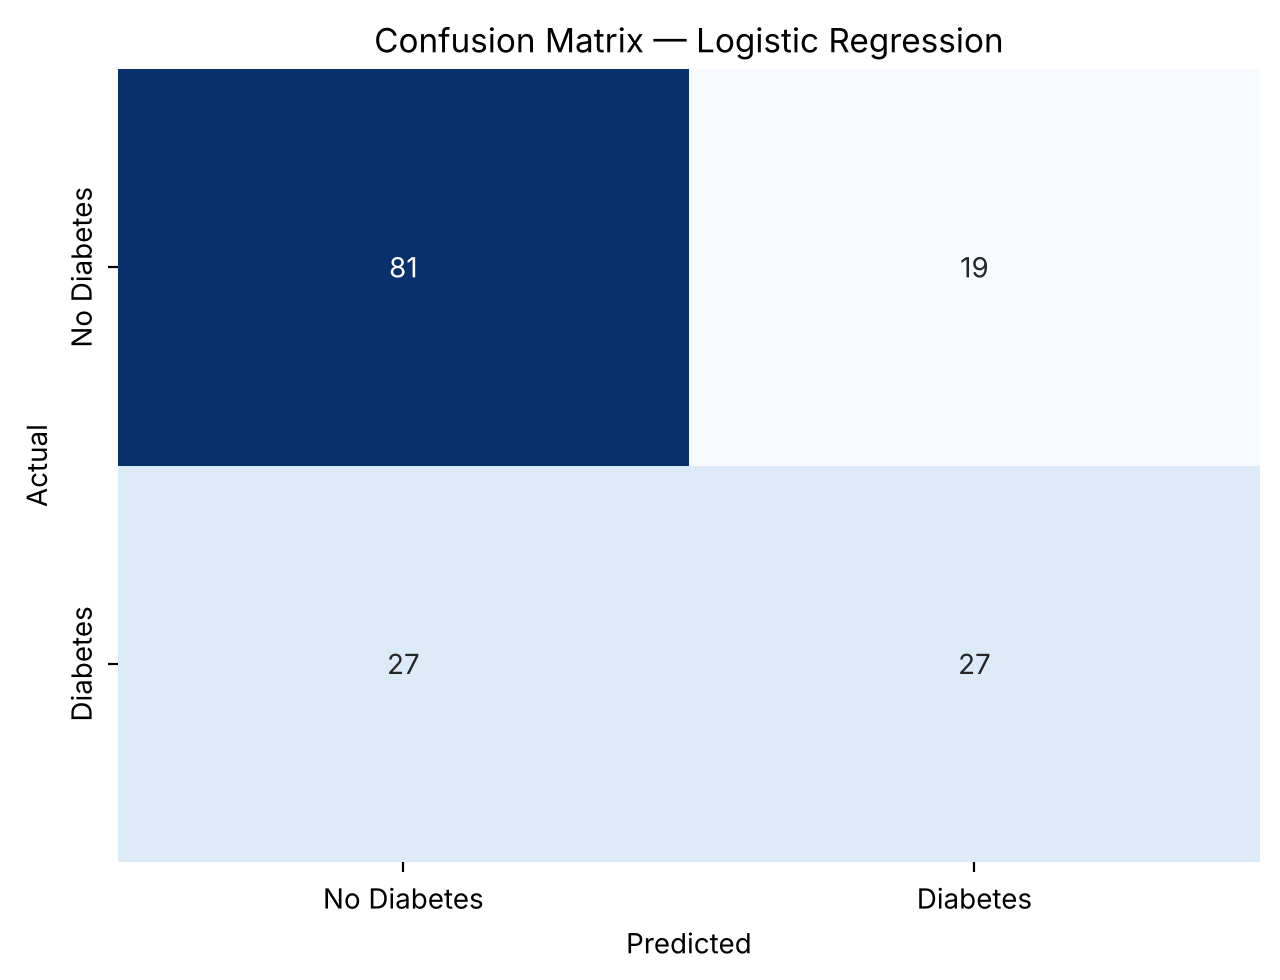

True Negatives :  81   correctly cleared
False Positives:  19   healthy flagged as diabetic (unnecessary test)
False Negatives:  27   MISSED DIABETICS  <-- the costly error
True Positives :  27   correctly detected

Sensitivity (Recall): 0.500  <- share of real diabetics caught
Specificity        : 0.810


In [18]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['No Diabetes','Diabetes'],
            yticklabels=['No Diabetes','Diabetes'])
ax.set(xlabel='Predicted', ylabel='Actual',
       title='Confusion Matrix — Logistic Regression')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negatives : {tn:>3}   correctly cleared")
print(f"False Positives: {fp:>3}   healthy flagged as diabetic (unnecessary test)")
print(f"False Negatives: {fn:>3}   MISSED DIABETICS  <-- the costly error")
print(f"True Positives : {tp:>3}   correctly detected")
print(f"\nSensitivity (Recall): {tp/(tp+fn):.3f}  <- share of real diabetics caught")
print(f"Specificity        : {tn/(tn+fp):.3f}")

**Reading the confusion matrix** (default 0.5 threshold)

- 81 healthy patients were correctly cleared, and 27 diabetics were correctly caught.
- 19 healthy patients were flagged unnecessarily. That costs one extra confirmatory test.
- **27 diabetics were missed.** This is the dangerous cell, because someone with the disease is told they're fine.
- Sensitivity is **0.50**: at the default threshold the model misses half of the true diabetics. Specificity is 0.81.
- In screening, a missed case costs far more than a false alarm, so the default threshold is the wrong one. Step 6 looks at moving it.

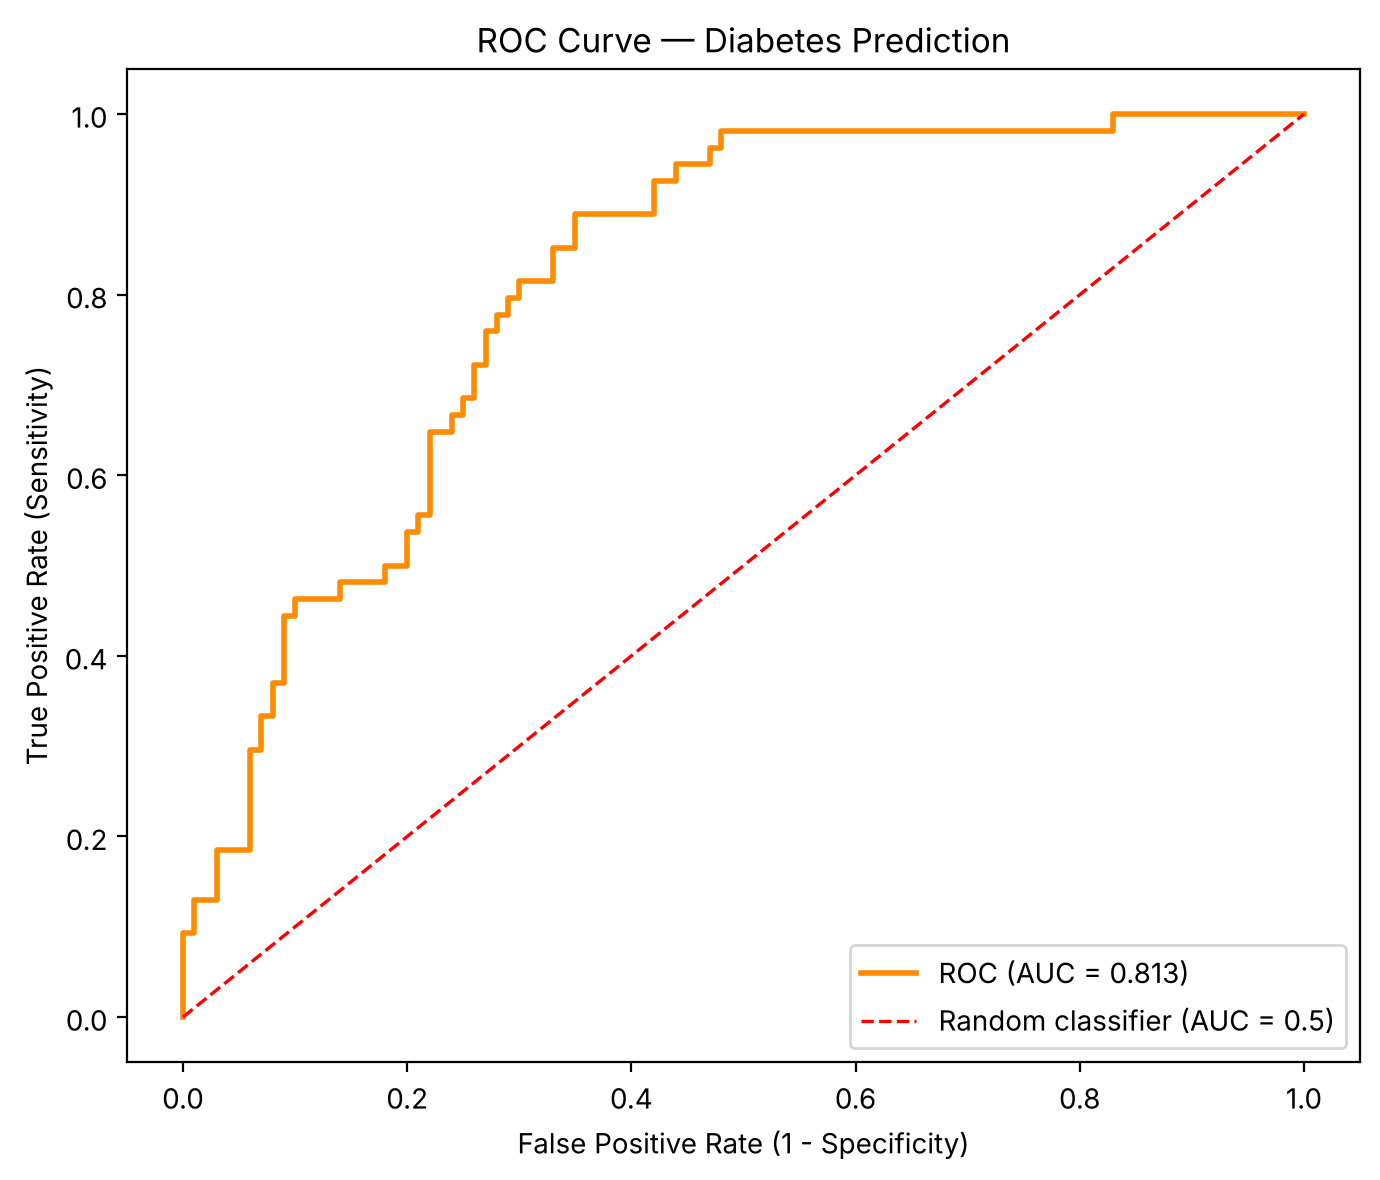

In [19]:
# ROC curve
fpr, tpr, thr = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {auc:.3f})')
ax.plot([0,1], [0,1], 'r--', lw=1.2, label='Random classifier (AUC = 0.5)')
ax.set(xlabel='False Positive Rate (1 - Specificity)',
       ylabel='True Positive Rate (Sensitivity)',
       title='ROC Curve — Diabetes Prediction')
ax.legend(loc='lower right')
plt.tight_layout(); plt.show()

**Reading the ROC curve**

- The curve sits well above the diagonal with **AUC = 0.81**. If you pick one diabetic and one non-diabetic at random, the model gives the diabetic the higher score about 81% of the time.
- AUC does not depend on any particular threshold, which makes it the right metric to check before choosing one.
- The steep early rise means the highest-scored patients are heavily enriched for true diabetics, which is what you want when the testing budget is limited.

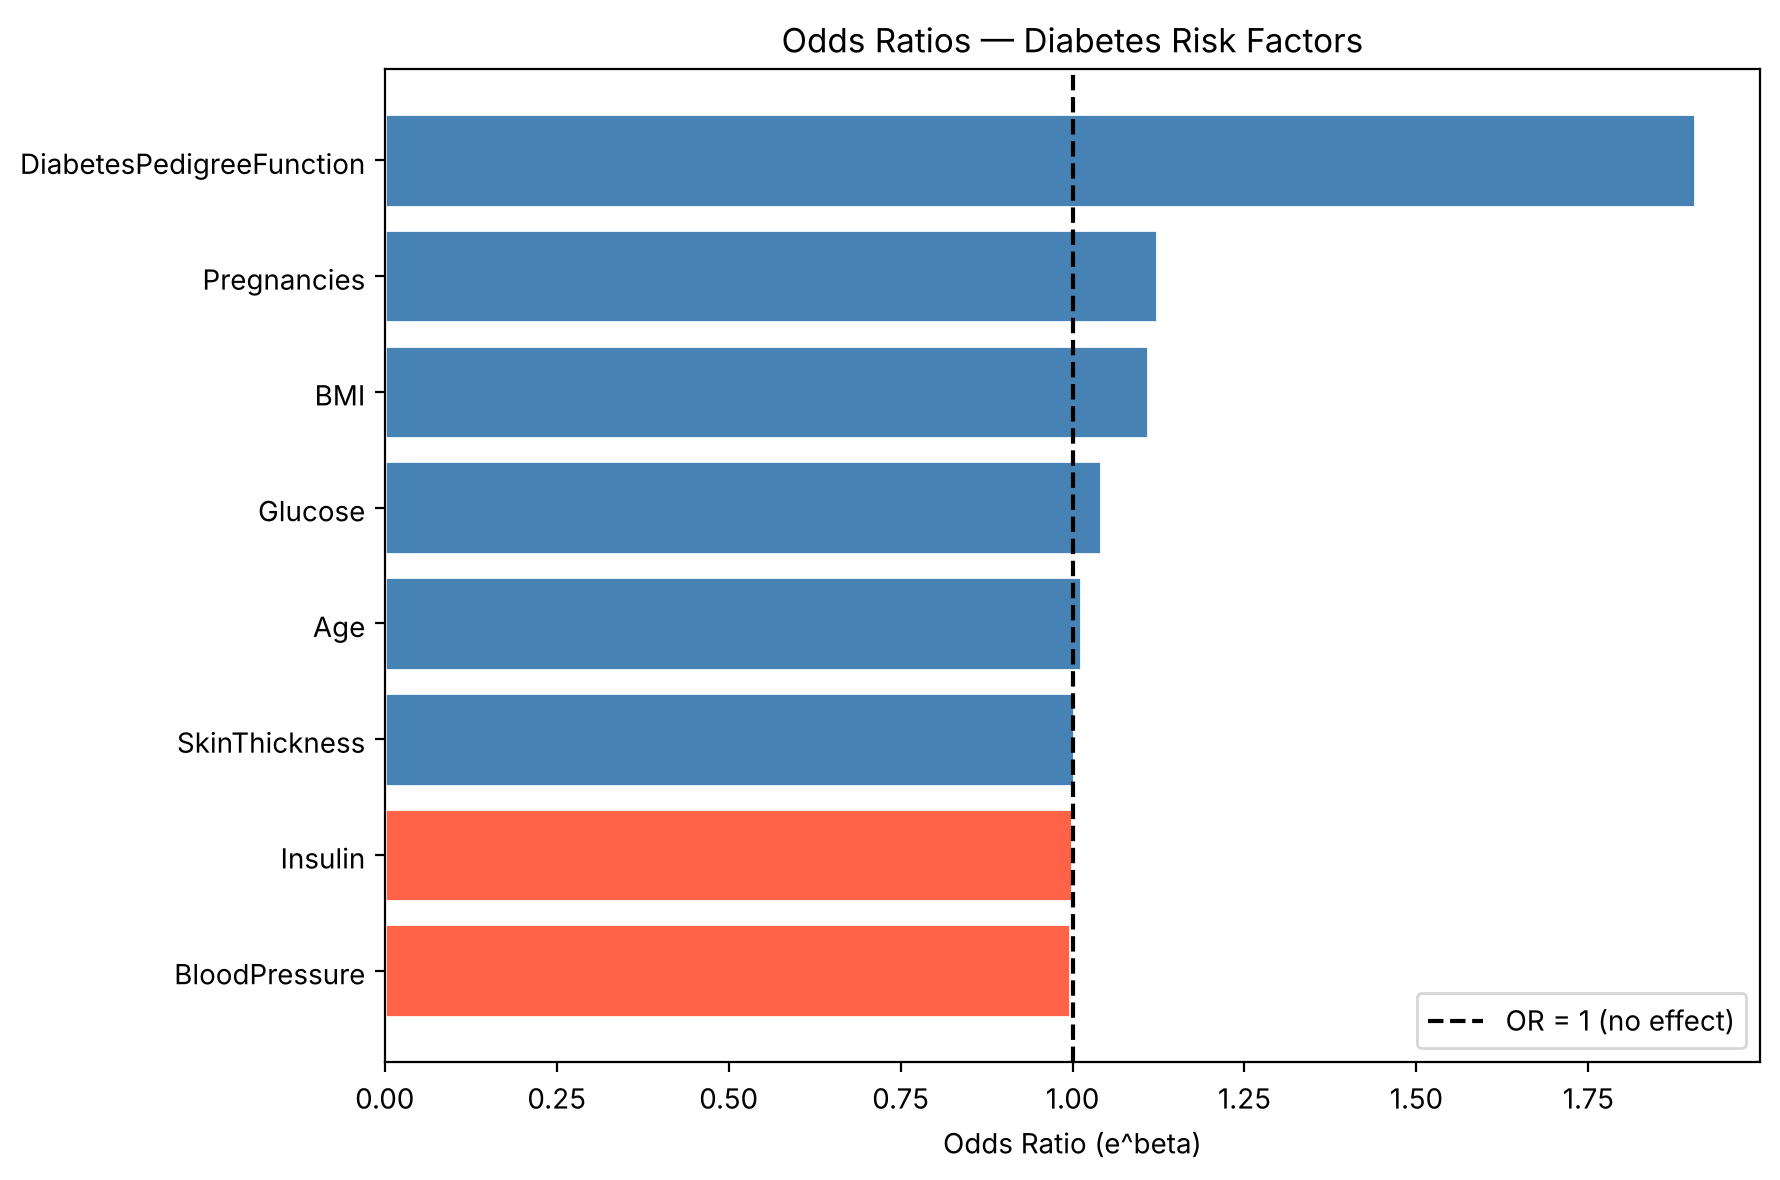

Blue = raises diabetes odds (OR > 1)
Red  = lowers diabetes odds (OR < 1)


In [20]:
# Odds ratio plot — the business-readable view of the coefficients
plot_df = coefficients.sort_values('Odds Ratio')
colours = ['tomato' if v < 1 else 'steelblue' for v in plot_df['Odds Ratio']]

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_df['Feature'], plot_df['Odds Ratio'], color=colours, edgecolor='white')
ax.axvline(1, color='black', ls='--', lw=1.5, label='OR = 1 (no effect)')
ax.set(xlabel='Odds Ratio (e^beta)', title='Odds Ratios — Diabetes Risk Factors')
ax.legend()
plt.tight_layout(); plt.show()

print("Blue = raises diabetes odds (OR > 1)")
print("Red  = lowers diabetes odds (OR < 1)")

**Reading the odds-ratio plot**

- The dashed line at OR = 1 is "no effect". Bars to the right raise risk; bars to the left lower it.
- **DiabetesPedigreeFunction** reaches furthest right (OR ≈ 1.9), but remember its wide confidence interval.
- Most other bars hug the line because they are measured in tiny units (one mg/dL, one year). Their effect over a realistic range is much bigger than the bar suggests.
- Only BloodPressure and Insulin fall left of the line, and neither is statistically significant.

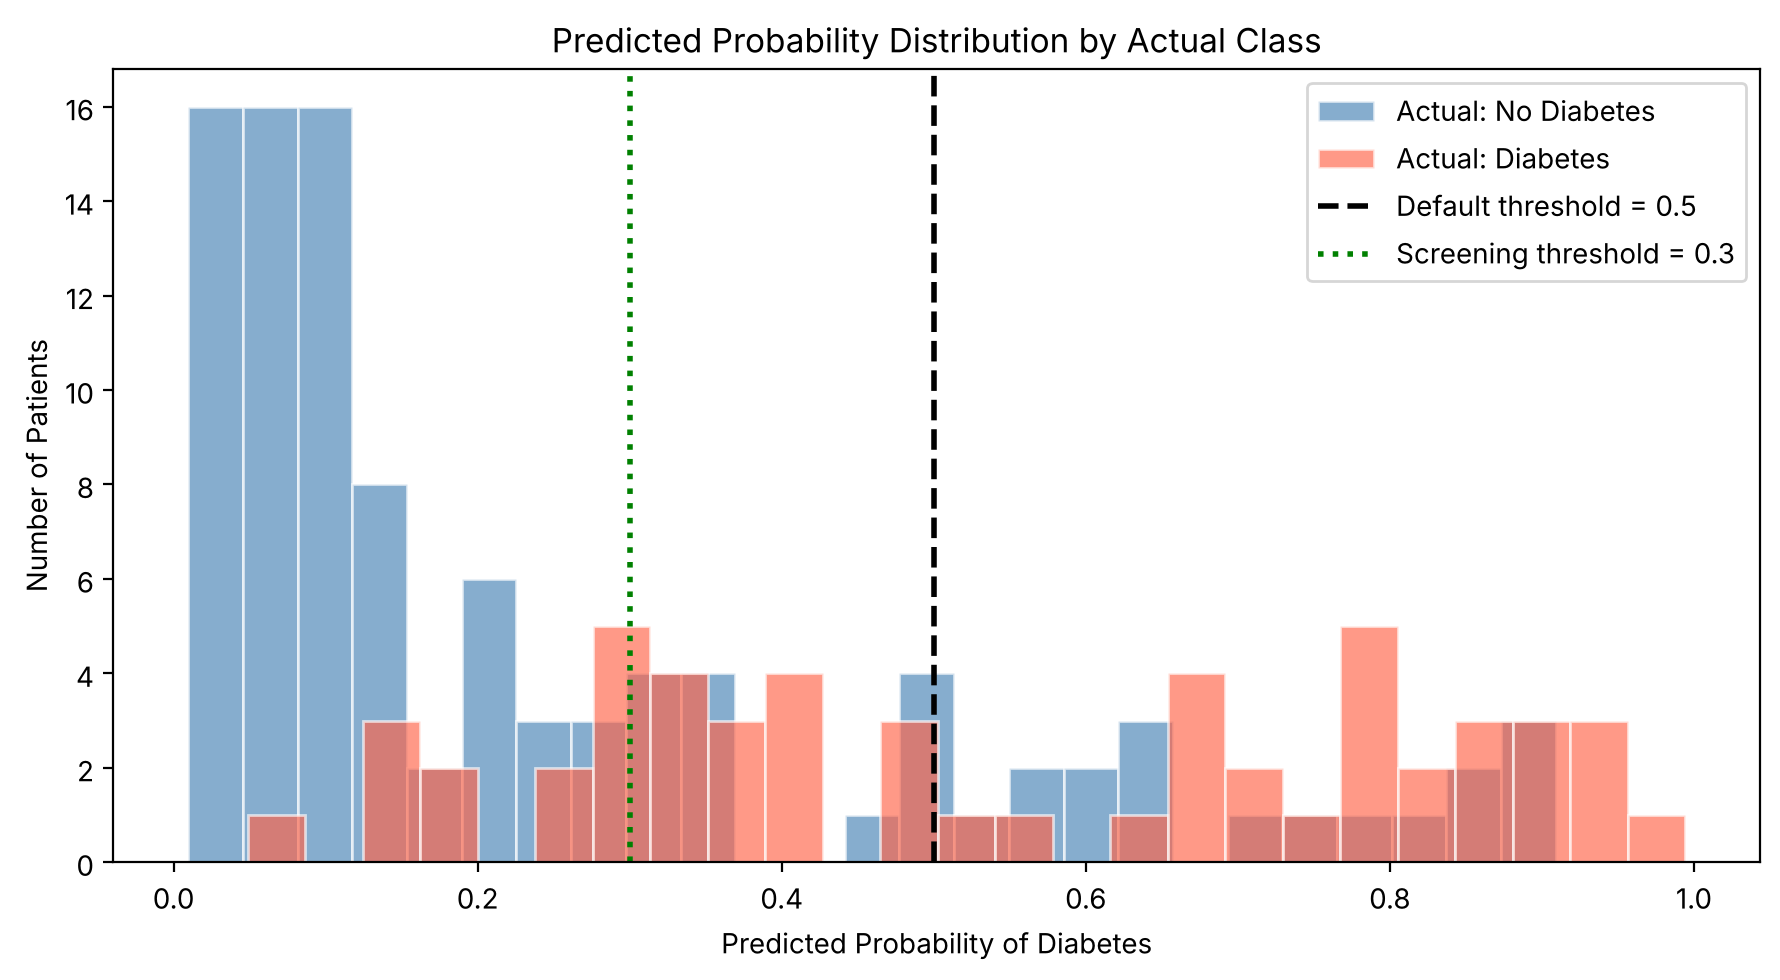

In [21]:
# Predicted probability distribution — where the threshold actually bites
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(y_proba[y_test==0], bins=25, alpha=0.65, color='steelblue',
        label='Actual: No Diabetes', edgecolor='white')
ax.hist(y_proba[y_test==1], bins=25, alpha=0.65, color='tomato',
        label='Actual: Diabetes', edgecolor='white')
ax.axvline(0.5, color='black', ls='--', lw=2, label='Default threshold = 0.5')
ax.axvline(0.3, color='green', ls=':', lw=2, label='Screening threshold = 0.3')
ax.set(xlabel='Predicted Probability of Diabetes', ylabel='Number of Patients',
       title='Predicted Probability Distribution by Actual Class')
ax.legend()
plt.tight_layout(); plt.show()

**Graph Interpretation — Predicted Probability Distribution:**
- The two classes **overlap in the middle**— that overlap is precisely the model's
  error region, and no threshold can eliminate it.
- Red bars (true diabetics) sitting **left of the black 0.5 line**are the false negatives.
- **Sliding the threshold to 0.3 (green line) reclassifies many of those red bars as
  positive**, raising sensitivity at the cost of more false positives.
- This single chart is the visual justification for the threshold recommendation in Step 7.

In [22]:
# Quantify the threshold trade-off
print(f"{'Threshold':>10} {'Sensitivity':>12} {'Specificity':>12} {'Missed':>8} {'FalseAlarm':>11}")
print("-" * 56)
for t in [0.5, 0.4, 0.35, 0.3, 0.25]:
    pred_t = (y_proba >= t).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred_t).ravel()
    print(f"{t:>10.2f} {tp_/(tp_+fn_):>12.3f} {tn_/(tn_+fp_):>12.3f} {fn_:>8} {fp_:>11}")

 Threshold  Sensitivity  Specificity   Missed  FalseAlarm
--------------------------------------------------------
      0.50        0.500        0.810       27          19
      0.40        0.611        0.780       21          22
      0.35        0.685        0.740       17          26
      0.30        0.796        0.700       11          30
      0.25        0.852        0.650        8          35


**Reading the threshold table**

On this test set (54 true diabetics, 100 healthy patients):

| Threshold | Diabetics missed | False alarms | Sensitivity | Specificity |
|-----------|-----------------|--------------|-------------|-------------|
| 0.50 | 27 | 19 | 0.50 | 0.81 |
| 0.30 | 11 | 30 | 0.80 | 0.70 |
| 0.25 | 8 | 35 | 0.85 | 0.65 |

Moving from 0.5 to 0.3 catches **16 more diabetics** at the price of **11 more false alarms**. If a false alarm costs one blood test and a miss costs years of untreated disease, that is an easy trade.

One caveat: I'm reading these thresholds off the same 154-patient test set I used for evaluation, and the counts are small. In a real deployment the threshold should be chosen on a separate validation set, ideally using actual cost figures.

## Step 7 — Business Interpretation & Suggestions

### What the model tells us

**1. Glucose and BMI carry the strongest evidence.**
Glucose is the most statistically solid predictor (z = 8.8). A patient 30 mg/dL higher than another has roughly 3.3 times the odds of testing positive. BMI is next (z = 5.0).

**2. Family history has the biggest per-unit effect, but the least certain one.**
`DiabetesPedigreeFunction` has an odds ratio of about 1.9 (p = 0.033). It is also the cheapest variable in the workflow, since it comes from asking the patient. Treat the size of its effect as approximate.

**3. BMI is the one risk factor a clinician can change.**
A 5-point lower BMI corresponds to odds about 40% lower (e^(−0.1037 × 5) ≈ 0.60). This is an association in observational data, not proof that losing weight will produce that exact reduction, but it points to where intervention effort is best spent.

**4. Pregnancies matters; Age mostly doesn't, once other factors are in.**
Pregnancies is significant (p = 0.002). Age is not (p = 0.236), probably because it overlaps with Pregnancies (r = 0.54).

**5. BloodPressure, SkinThickness and Insulin add nothing detectable.**
None is significant. Insulin is also unreliable because about 49% of its values were imputed. A cheaper screening panel could leave all three out.

**6. The default 0.5 threshold is wrong for screening.**
At 0.5 the model misses half of the diabetics. Accuracy is a poor objective when the two kinds of error have very different costs.

### Recommendations

1. **Lower the screening threshold to around 0.3**, and set it properly on a validation set using real cost estimates.
2. **Use a short pre-screen built on glucose, BMI, family history and pregnancy history.** These carry nearly all of the signal and could triage patients before the full panel.
3. **Aim weight-management programmes at high-BMI patients.** Age and genetics identify risk; BMI is where an intervention can change it.
4. **Fix the data capture.** Roughly half of Insulin and 30% of SkinThickness were recorded as zero. Without fixing that, we can't tell whether those markers matter.
5. **Don't use this as a diagnostic.** An AUC of 0.81 is good for deciding who to test first, not for replacing the test.

## Step 8 — Conclusion

### Summary

| Metric | Value | Assessment |
|--------|-------|------------|
| Accuracy | 0.701 | Only 5 points above the 65% "always no" baseline, so not the headline number |
| ROC-AUC | 0.813 | Good discrimination; the metric that matters here |
| Pseudo-R² (McFadden) | 0.299 | Strong for a logit model |
| Model significance | p ≈ 7 × 10⁻⁴⁷ | Significant overall |
| EPV | 33.5 | Well above the minimum of 10 |

### Risk factors, by strength of evidence

| Rank | Factor | Odds ratio | p-value | Modifiable? |
|------|--------|-----------|---------|-------------|
| 1 | Glucose | 1.04 per mg/dL | < 0.001 | Partly |
| 2 | BMI | 1.11 per point | < 0.001 | **Yes** |
| 3 | Pregnancies | 1.12 per pregnancy | 0.002 | No |
| 4 | DiabetesPedigreeFunction | 1.90 per unit | 0.033 | No (genetic) |
| n.s. | Age, BloodPressure, SkinThickness, Insulin | about 1.0 | > 0.2 | n/a |

### Conclusion

Glucose, BMI, pregnancy history and family history are the factors that matter in this cohort. The model ranks patients well (AUC 0.81) and works as a **triage tool** for deciding who to test first. It is not a diagnostic replacement. The most practical finding is that BMI is the modifiable lever.

**Next steps:** fix zero-coding at data capture; add HbA1c and waist circumference; validate with stratified k-fold cross-validation; and calibrate the threshold against the real cost of a missed case versus a false alarm.
